# GCAT + Weather EDA

Exploratory data analysis of launch records enriched with Open-Meteo historical weather data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the merged dataset
df = pd.read_csv('../data/merged_gcat_meteo.csv', low_memory=False)

# 2. Display basic info
print(f"Total rows: {len(df)}")
print("\n--- Missing Weather Data Count ---")
print(df[['temp_mean', 'precipitation', 'max_wind_speed']].isna().sum())

# 3. Preview the first 5 rows
df.head()


Total rows: 17063

--- Missing Weather Data Count ---
temp_mean         3470
precipitation     3470
max_wind_speed    3470
dtype: int64


,#Launch_Tag,Launch_JD,Launch_Date,LV_Type,Variant,Flight_ID,Flight,Mission,FlightCode,Platform,...,Harmonized_Outcome,Launch_Year,Source_File,#Site,Latitude,Longitude,temp_mean,precipitation,max_wind_speed,api_status
0,1942-S01,2430636.12,1942-10-03,A-4,NaN,4,NaN,NaN,NaN,NaN,...,NaN,1942.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,11.4,0.2,15.3,SUCCESS
1,1943-S03,2430837.10,1943-04-22,A-4,NaN,21,NaN,NaN,NaN,NaN,...,NaN,1943.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,13.9,0.0,30.0,SUCCESS
2,1943-S05,2430870.96,1943-05-26,A-4,NaN,26,NaN,NaN,NaN,NaN,...,NaN,1943.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,12.7,2.8,19.1,SUCCESS
3,1944-S31,2431316.17,1944-08-13,V-2,NaN,18296,Ma100,NaN,NaN,NaN,...,NaN,1944.0,Exoatmospheric Suborbital Launches.tsv,HKR,53.600,18.000,17.8,0.0,15.8,SUCCESS
4,1944-S32,2431316.26,1944-08-13,V-2,NaN,18292,Ma106,NaN,NaN,NaN,...,NaN,1944.0,Exoatmospheric Suborbital Launches.tsv,HKR,53.600,18.000,17.8,0.0,15.8,SUCCESS


Rows after cleaning: 13593

--- All Columns in Dataset ---
#Launch_Tag
Launch_JD
Launch_Date
LV_Type
Variant
Flight_ID
Flight
Mission
FlightCode
Platform
Launch_Site
Launch_Pad
Ascent_Site
Ascent_Pad
Apoflag
Range
RangeFlag
Dest
OrbPay
Agency
LaunchCode
FailCode
Group
Category
LTCite
Cite
Launch_Category
Is_Orbital_Attempt
Harmonized_Outcome
Launch_Year
Source_File
#Site
Latitude
Longitude
temp_mean
precipitation
max_wind_speed
api_status


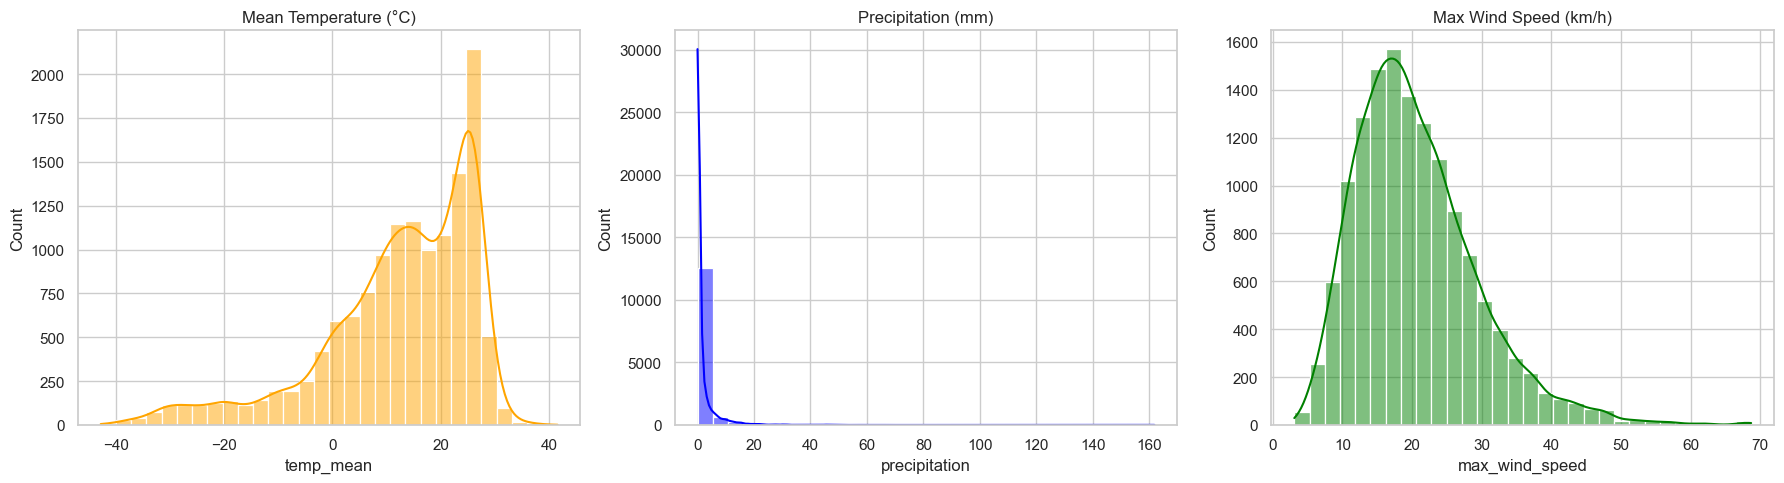

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Drop the 3,470 rows where weather data couldn't be fetched
df_clean = df.dropna(subset=['temp_mean', 'precipitation', 'max_wind_speed']).copy()
print(f"Rows after cleaning: {len(df_clean)}")

# 2. Print all column names so we can find the "Success/Failure" column
print("\n--- All Columns in Dataset ---")
for col in df_clean.columns:
    print(col)

# 3. Plot Weather Distributions
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_clean['temp_mean'], bins=30, kde=True, ax=axes[0], color='orange')
axes[0].set_title('Mean Temperature (°C)')

sns.histplot(df_clean['precipitation'], bins=30, kde=True, ax=axes[1], color='blue')
axes[1].set_title('Precipitation (mm)')

sns.histplot(df_clean['max_wind_speed'], bins=30, kde=True, ax=axes[2], color='green')
axes[2].set_title('Max Wind Speed (km/h)')

plt.tight_layout()
plt.show()


--- Launch Outcomes Breakdown ---
Outcome
Success            12783
Failure/Anomaly      810
Name: count, dtype: int64


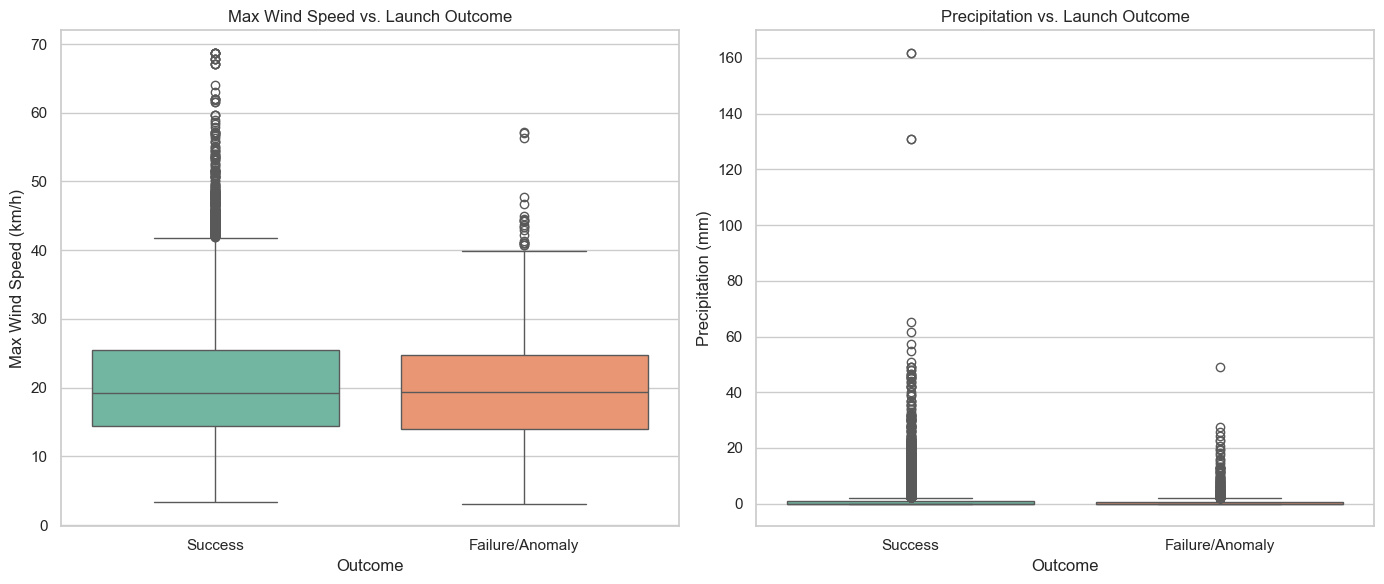

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Create a clean 'Outcome' column
# If FailCode has a value (not NA), it's a failure. If it is empty (NA), it's a success.
df_clean['Outcome'] = df_clean['FailCode'].apply(lambda x: 'Failure/Anomaly' if pd.notna(x) else 'Success')

# Check the exact text and counts for our new Outcome column
print("--- Launch Outcomes Breakdown ---")
print(df_clean['Outcome'].value_counts())

# 2. Visualize Weather vs. Launch Outcome (Fixed Seaborn Syntax)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot for Wind Speed (Added hue='Outcome' and legend=False to fix the warning)
sns.boxplot(
    x='Outcome', 
    y='max_wind_speed', 
    data=df_clean, 
    ax=axes[0], 
    palette='Set2',
    hue='Outcome',
    legend=False
)
axes[0].set_title('Max Wind Speed vs. Launch Outcome')
axes[0].set_ylabel('Max Wind Speed (km/h)')

# Boxplot for Precipitation
sns.boxplot(
    x='Outcome', 
    y='precipitation', 
    data=df_clean, 
    ax=axes[1], 
    palette='Set2',
    hue='Outcome',
    legend=False
)
axes[1].set_title('Precipitation vs. Launch Outcome')
axes[1].set_ylabel('Precipitation (mm)')

plt.tight_layout()
plt.show()


In [4]:
# 1. Select only the features relevant for predicting launch outcomes
features = ['temp_mean', 'precipitation', 'max_wind_speed', 'Launch_Site', 'LV_Type', 'Agency']
target = 'Outcome'

# Create a focused dataframe
ml_df = df_clean[features + [target]].copy()

# 2. Drop any rows that might be missing Launch Site, Rocket Type, or Agency data
ml_df = ml_df.dropna()

# 3. Convert Target to Binary format for the ML Model
# 1 = Failure/Anomaly (The event we want the model to learn to detect), 0 = Success
ml_df['Target'] = ml_df['Outcome'].map({'Failure/Anomaly': 1, 'Success': 0})
ml_df = ml_df.drop(columns=['Outcome'])

print(f"Final ML Dataset Shape: {ml_df.shape}")
print("\n--- Target Variable Percentage (Class Balance) ---")
print(ml_df['Target'].value_counts(normalize=True) * 100) 
print("\n--- Target Variable Raw Counts ---")
print(ml_df['Target'].value_counts())


Final ML Dataset Shape: (13593, 7)

--- Target Variable Percentage (Class Balance) ---
Target
0    94.041051
1     5.958949
Name: proportion, dtype: float64

--- Target Variable Raw Counts ---
Target
0    12783
1      810
Name: count, dtype: int64


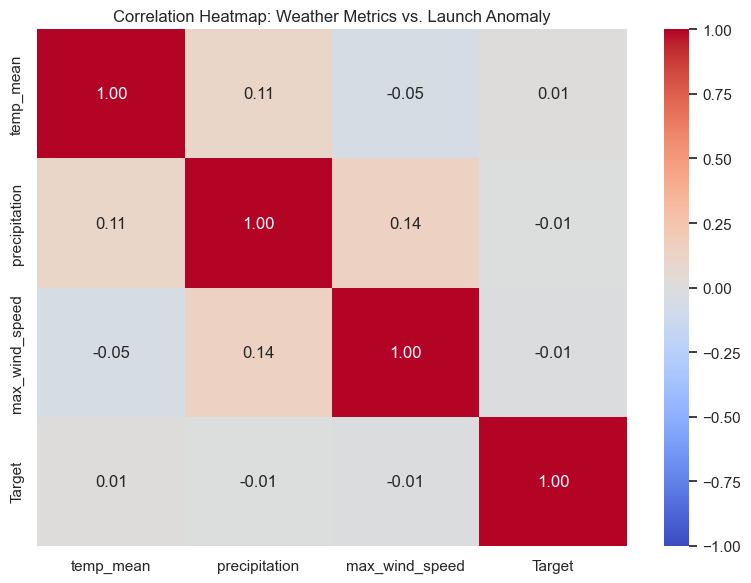

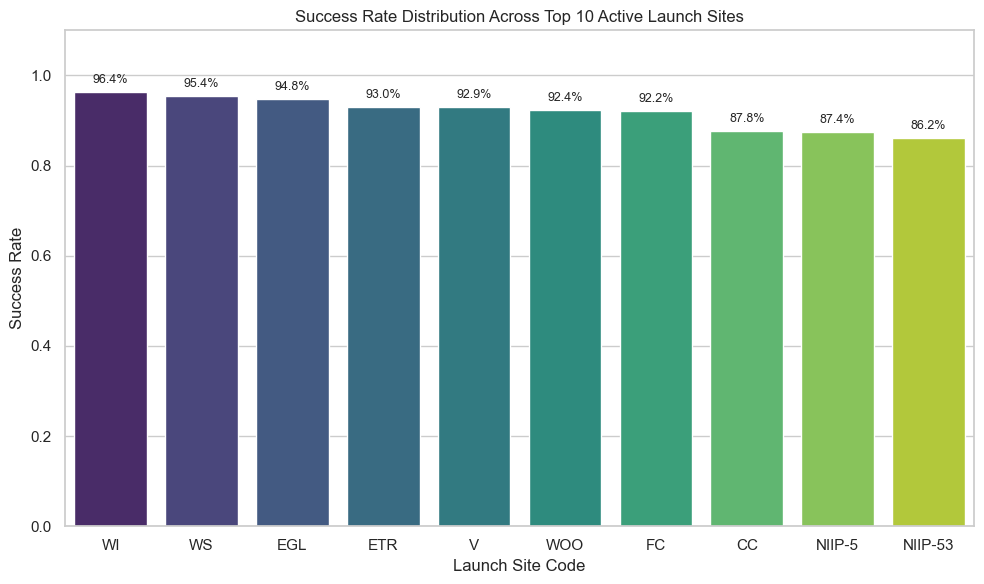

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
# Calculate correlation between weather metrics and our binary ML target (1=Failure, 0=Success)
corr_matrix = ml_df[['temp_mean', 'precipitation', 'max_wind_speed', 'Target']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap: Weather Metrics vs. Launch Anomaly')
plt.tight_layout()
plt.show()

# 2. Success Rate Distribution by Top 10 Launch Sites
plt.figure(figsize=(10, 6))
# Get the top 10 most active launch sites
top_sites = df_clean['Launch_Site'].value_counts().head(10).index
top_sites_data = df_clean[df_clean['Launch_Site'].isin(top_sites)]

# Calculate success rate per site
site_stats = top_sites_data.groupby('Launch_Site')['Outcome'].value_counts(normalize=True).unstack().fillna(0)
if 'Success' in site_stats.columns:
    site_success = site_stats['Success'].sort_values(ascending=False)
    
    sns.barplot(x=site_success.index, y=site_success.values, palette='viridis', hue=site_success.index, legend=False)
    plt.title('Success Rate Distribution Across Top 10 Active Launch Sites')
    plt.ylabel('Success Rate')
    plt.xlabel('Launch Site Code')
    plt.ylim(0, 1.1)
    
    # Add percentage labels on top of bars
    for i, v in enumerate(site_success.values):
        plt.text(i, v + 0.02, f"{v:.1%}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the merged dataset
df = pd.read_csv('../data/merged_gcat_meteo.csv', low_memory=False)

# Check the exact shape and missing data
print(f"Total rows: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print("\n--- Missing Data Breakdown ---")
missing_data = df.isna().sum()
print(missing_data[missing_data > 0]) # Only show columns with missing data


Total rows: 17063
Total columns: 38

--- Missing Data Breakdown ---
Variant               16217
Flight_ID              3428
Flight                 3990
Mission               12266
FlightCode            15979
Platform              16030
Launch_Pad             8611
Ascent_Site           16976
Ascent_Pad            16974
Apoflag               17063
RangeFlag             17063
Dest                  15185
FailCode              15855
Group                  4993
Category                 15
LTCite                    1
Cite                  11825
Launch_Category       17063
Is_Orbital_Attempt    17063
Harmonized_Outcome    17063
Launch_Year            2385
temp_mean              3470
precipitation          3470
max_wind_speed         3470
dtype: int64


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_FILE = "../data/merged_gcat_meteo.csv"
df = pd.read_csv(DATA_FILE, low_memory=False)

df["Launch_Date"] = pd.to_datetime(df["Launch_Date"], errors="coerce")
df.head()

,#Launch_Tag,Launch_JD,Launch_Date,LV_Type,Variant,Flight_ID,Flight,Mission,FlightCode,Platform,...,Harmonized_Outcome,Launch_Year,Source_File,#Site,Latitude,Longitude,temp_mean,precipitation,max_wind_speed,api_status
0,1942-S01,2430636.12,1942-10-03,A-4,NaN,4,NaN,NaN,NaN,NaN,...,NaN,1942.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,11.4,0.2,15.3,SUCCESS
1,1943-S03,2430837.10,1943-04-22,A-4,NaN,21,NaN,NaN,NaN,NaN,...,NaN,1943.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,13.9,0.0,30.0,SUCCESS
2,1943-S05,2430870.96,1943-05-26,A-4,NaN,26,NaN,NaN,NaN,NaN,...,NaN,1943.0,Exoatmospheric Suborbital Launches.tsv,HVP,54.173,13.801,12.7,2.8,19.1,SUCCESS
3,1944-S31,2431316.17,1944-08-13,V-2,NaN,18296,Ma100,NaN,NaN,NaN,...,NaN,1944.0,Exoatmospheric Suborbital Launches.tsv,HKR,53.600,18.000,17.8,0.0,15.8,SUCCESS
4,1944-S32,2431316.26,1944-08-13,V-2,NaN,18292,Ma106,NaN,NaN,NaN,...,NaN,1944.0,Exoatmospheric Suborbital Launches.tsv,HKR,53.600,18.000,17.8,0.0,15.8,SUCCESS


Rows after dropping missing weather: 13593


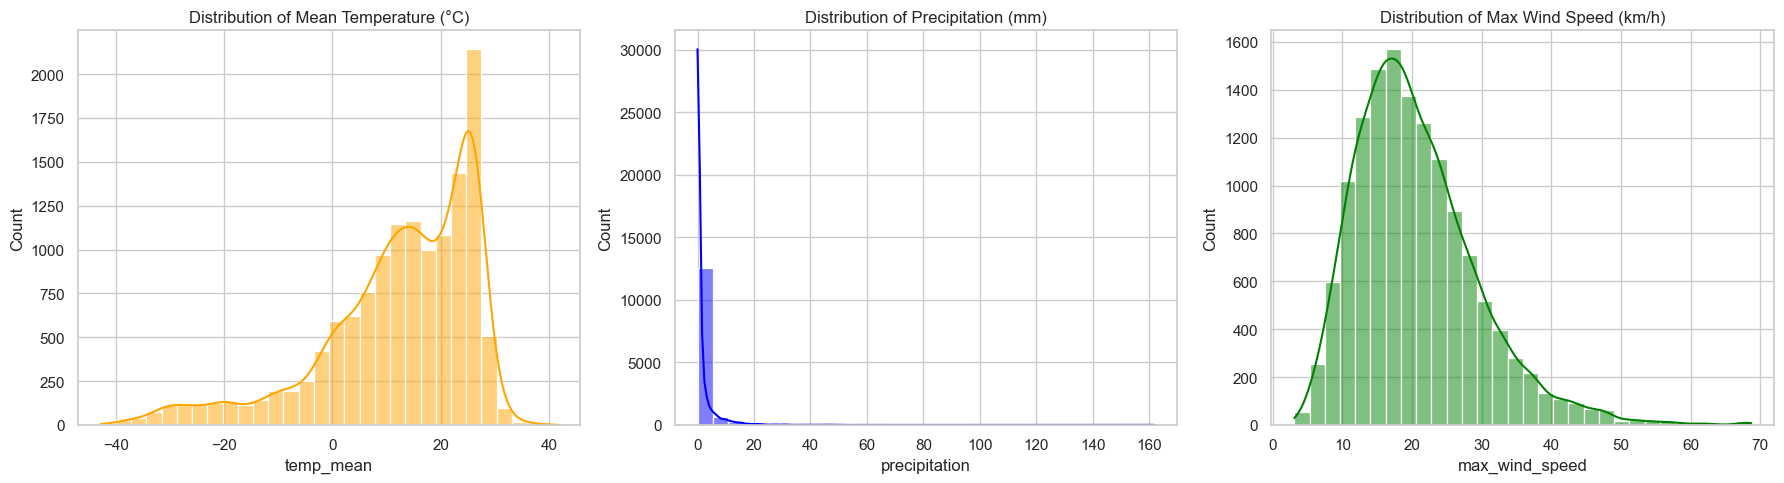

In [8]:
# 1. Drop rows where the weather API failed to return data
df_clean = df.dropna(subset=['temp_mean', 'precipitation', 'max_wind_speed']).copy()

print(f"Rows after dropping missing weather: {len(df_clean)}")

# 2. Set up the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 3. Plot Distributions
sns.histplot(df_clean['temp_mean'], bins=30, kde=True, ax=axes[0], color='orange')
axes[0].set_title('Distribution of Mean Temperature (°C)')

sns.histplot(df_clean['precipitation'], bins=30, kde=True, ax=axes[1], color='blue')
axes[1].set_title('Distribution of Precipitation (mm)')

sns.histplot(df_clean['max_wind_speed'], bins=30, kde=True, ax=axes[2], color='green')
axes[2].set_title('Distribution of Max Wind Speed (km/h)')

plt.tight_layout()
plt.show()


## Dataset overview

In [9]:
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Date range: {df['Launch_Date'].min()} to {df['Launch_Date'].max()}")
print(f"Unique launch sites: {df['Launch_Site'].nunique()}")

df.info()

Rows: 17,063
Columns: 38
Date range: 1942-06-13 00:00:00 to 2026-07-10 00:00:00
Unique launch sites: 308
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17063 entries, 0 to 17062
Data columns (total 38 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   #Launch_Tag         17063 non-null  object        
 1   Launch_JD           17063 non-null  float64       
 2   Launch_Date         17063 non-null  datetime64[ns]
 3   LV_Type             17063 non-null  object        
 4   Variant             846 non-null    object        
 5   Flight_ID           13635 non-null  object        
 6   Flight              13073 non-null  object        
 7   Mission             4797 non-null   object        
 8   FlightCode          1084 non-null   object        
 9   Platform            1033 non-null   object        
 10  Launch_Site         17063 non-null  object        
 11  Launch_Pad          8452 non-null   object        
 1

## Weather enrichment quality

In [10]:
weather_cols = ["temp_mean", "precipitation", "max_wind_speed"]

print("API status counts:")
print(df["api_status"].value_counts())

print("\nMissing weather values:")
print(df[weather_cols].isna().sum())

df[weather_cols].describe()

API status counts:
api_status
SUCCESS                  13593
RATE_LIMITED              3460
ERROR_ConnectionError        5
ERROR_ReadTimeout            5
Name: count, dtype: int64

Missing weather values:
temp_mean         3470
precipitation     3470
max_wind_speed    3470
dtype: int64


,temp_mean,precipitation,max_wind_speed
count,13593.000000,13593.000000,13593.000000
mean,12.270713,1.488104,20.612477
std,14.109918,4.818871,8.789604
min,-42.800000,0.000000,3.100000
25%,5.600000,0.000000,14.400000
50%,15.100000,0.000000,19.200000
75%,23.700000,0.900000,25.300000
max,41.600000,161.800000,68.700000


## Weather distributions

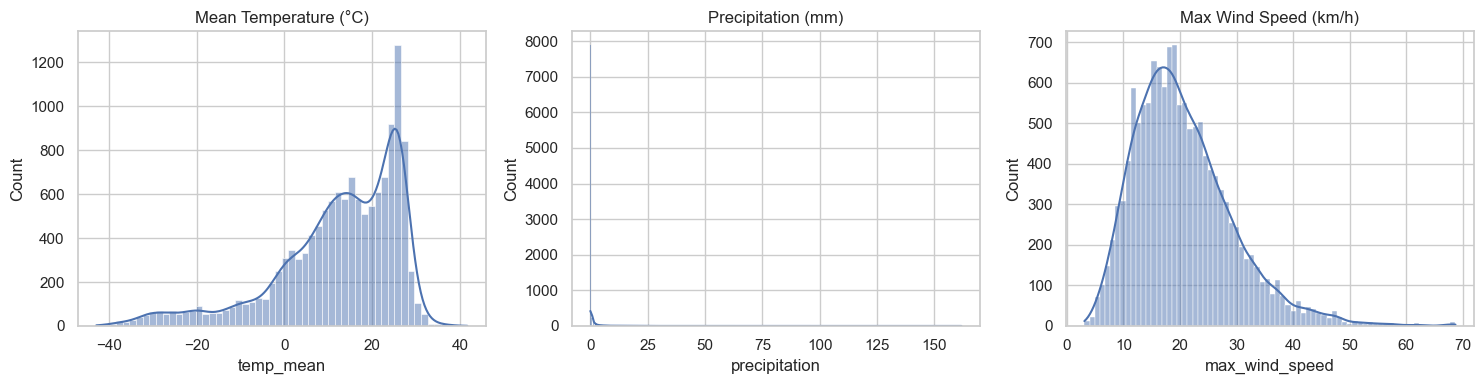

In [11]:
success_df = df[df["api_status"] == "SUCCESS"].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(success_df["temp_mean"], kde=True, ax=axes[0])
axes[0].set_title("Mean Temperature (°C)")

sns.histplot(success_df["precipitation"], kde=True, ax=axes[1])
axes[1].set_title("Precipitation (mm)")

sns.histplot(success_df["max_wind_speed"], kde=True, ax=axes[2])
axes[2].set_title("Max Wind Speed (km/h)")

plt.tight_layout()
plt.show()

## Launches over time

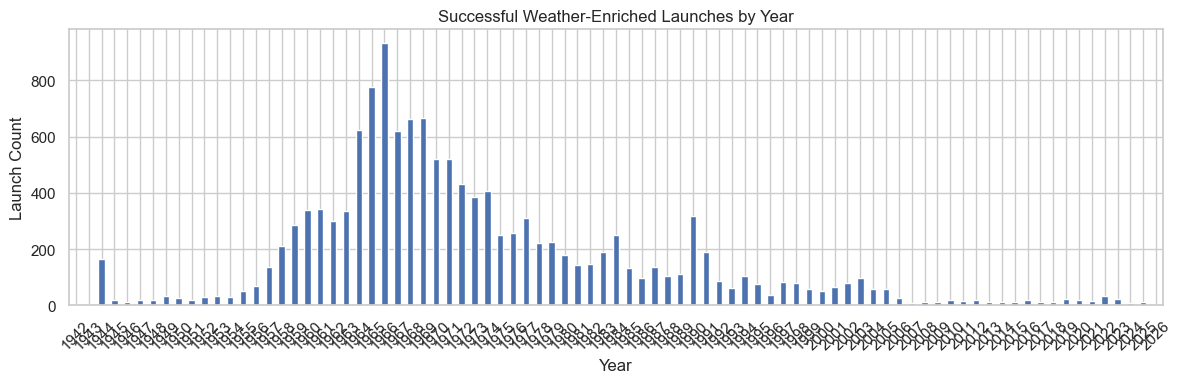

In [12]:
launches_by_year = success_df.groupby(success_df["Launch_Date"].dt.year).size()

plt.figure(figsize=(12, 4))
launches_by_year.plot(kind="bar")
plt.title("Successful Weather-Enriched Launches by Year")
plt.xlabel("Year")
plt.ylabel("Launch Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Top launch sites

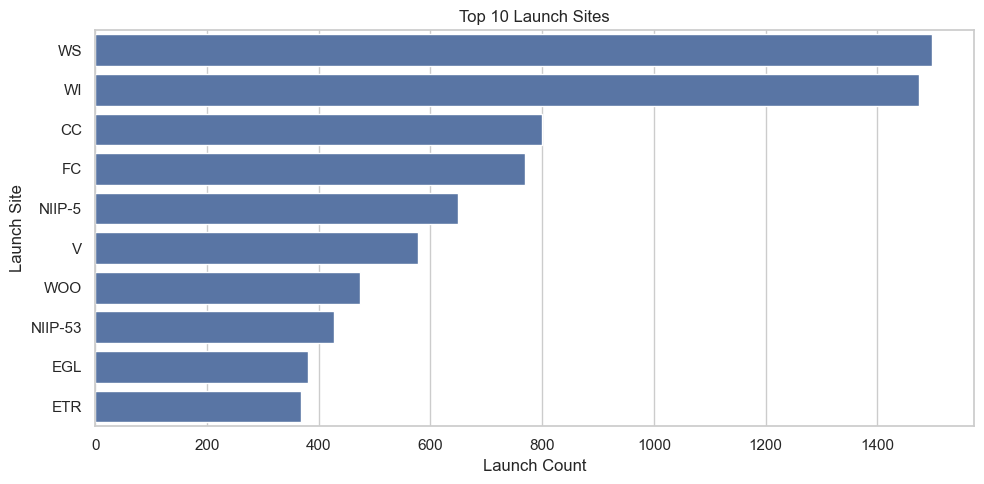

In [13]:
top_sites = success_df["Launch_Site"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_sites.values, y=top_sites.index)
plt.title("Top 10 Launch Sites")
plt.xlabel("Launch Count")
plt.ylabel("Launch Site")
plt.tight_layout()
plt.show()

## Weather vs launch outcome

,temp_mean,precipitation,max_wind_speed
Harmonized_Outcome,,,


ValueError: List of boxplot statistics and `positions` values must have same the length

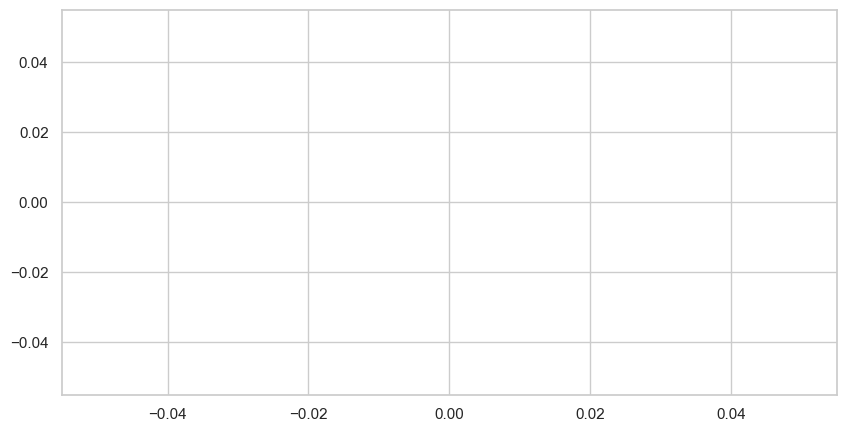

In [14]:
if "Harmonized_Outcome" in success_df.columns:
    outcome_weather = (
        success_df.groupby("Harmonized_Outcome")[weather_cols]
        .mean()
        .sort_values("temp_mean", ascending=False)
    )
    display(outcome_weather)

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=success_df, x="Harmonized_Outcome", y="max_wind_speed")
    plt.title("Max Wind Speed by Launch Outcome")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Harmonized_Outcome column not available.")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separate Features (X) and Target (y)
X = ml_df.drop('Target', axis=1)
y = ml_df['Target']

# 2. One-Hot Encoding for Categorical Variables
categorical_cols = ['Launch_Site', 'LV_Type', 'Agency']
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# 3. Train-Test Split (with Stratification)
# 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling (Standardization)
scaler = StandardScaler()
weather_cols = ['temp_mean', 'precipitation', 'max_wind_speed']

# Fit the scaler ONLY on the training data, then transform both
X_train[weather_cols] = scaler.fit_transform(X_train[weather_cols])
X_test[weather_cols] = scaler.transform(X_test[weather_cols])

# 5. Output the results
print(f"Original dataset shape: {ml_df.shape}")
print(f"Features shape after One-Hot Encoding: {X_encoded.shape}")
print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape: {X_test.shape}")
print("\n--- Training Set Class Balance (Should still be ~94% / 6%) ---")
print(y_train.value_counts(normalize=True) * 100)


Original dataset shape: (13593, 7)
Features shape after One-Hot Encoding: (13593, 1288)
Training set features shape: (10874, 1288)
Testing set features shape: (2719, 1288)

--- Training Set Class Balance (Should still be ~94% / 6%) ---
Target
0    94.040831
1     5.959169
Name: proportion, dtype: float64


Training the Random Forest model...

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      2557
           1       0.26      0.09      0.13       162

    accuracy                           0.93      2719
   macro avg       0.60      0.54      0.55      2719
weighted avg       0.90      0.93      0.91      2719



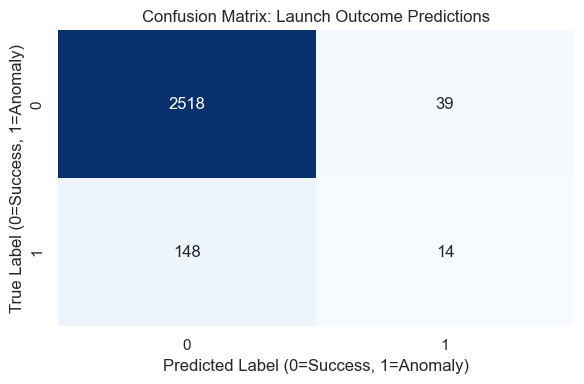

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Initialize the Random Forest model
# class_weight='balanced' automatically adjusts weights inversely proportional to class frequencies
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)

# 2. Train the model on the scaled training data
print("Training the Random Forest model...")
rf_model.fit(X_train, y_train)

# 3. Make predictions on the unseen testing data
y_pred = rf_model.predict(X_test)

# 4. Print the Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 5. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix: Launch Outcome Predictions')
plt.xlabel('Predicted Label (0=Success, 1=Anomaly)')
plt.ylabel('True Label (0=Success, 1=Anomaly)')
plt.tight_layout()
plt.show()


Training the Logistic Regression Baseline model...

--- Logistic Regression Baseline: Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.74      0.84      2557
           1       0.12      0.56      0.20       162

    accuracy                           0.73      2719
   macro avg       0.54      0.65      0.52      2719
weighted avg       0.91      0.73      0.80      2719



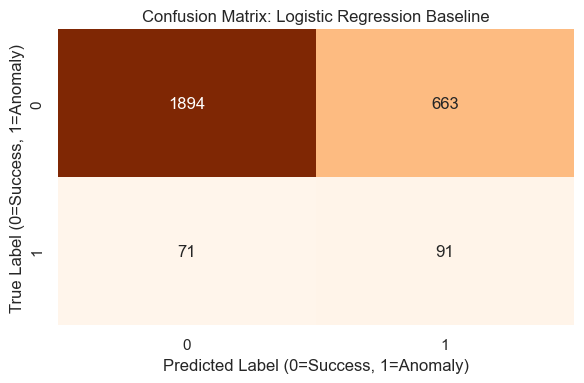

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize the Logistic Regression baseline model
# max_iter=1000 ensures the algorithm converges with our 1,288 One-Hot Encoded columns
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# 2. Train the baseline model
print("Training the Logistic Regression Baseline model...")
lr_model.fit(X_train, y_train)

# 3. Make predictions
lr_y_pred = lr_model.predict(X_test)

# 4. Print the Classification Report
print("\n--- Logistic Regression Baseline: Classification Report ---")
print(classification_report(y_test, lr_y_pred))

# 5. Visualize the Confusion Matrix
lr_cm = confusion_matrix(y_test, lr_y_pred)
plt.figure(figsize=(6, 4))
# Using a different color map (Oranges) so it looks distinct from the RF model in your report
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Oranges', cbar=False) 
plt.title('Confusion Matrix: Logistic Regression Baseline')
plt.xlabel('Predicted Label (0=Success, 1=Anomaly)')
plt.ylabel('True Label (0=Success, 1=Anomaly)')
plt.tight_layout()
plt.show()


/var/folders/_b/bqwf7pwn3xx9b0cpgsgnl9_80000gn/T/ipykernel_94830/3903036558.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')


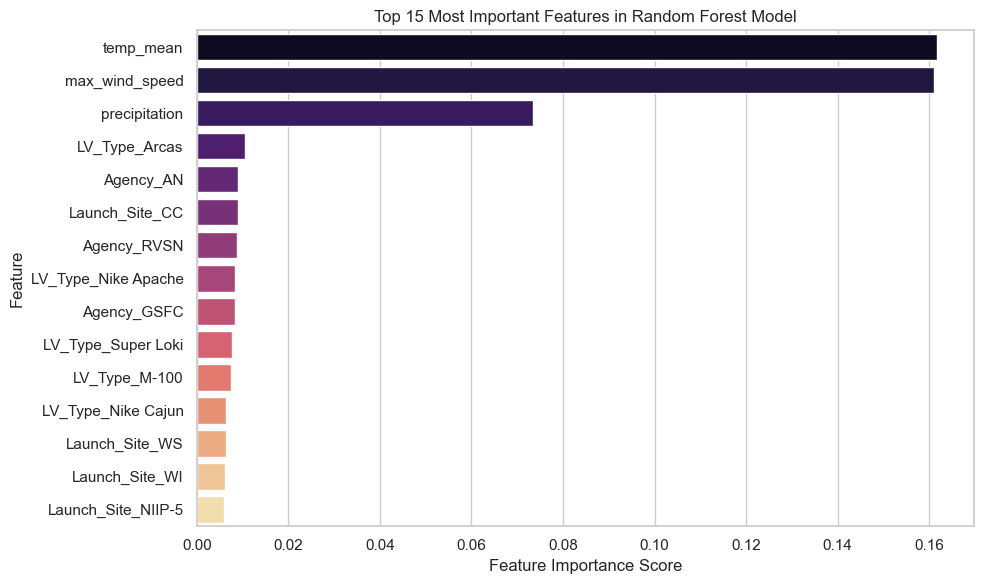

--- Top 15 Features Breakdown ---
            Feature  Importance
          temp_mean    0.161679
     max_wind_speed    0.160927
      precipitation    0.073357
      LV_Type_Arcas    0.010456
          Agency_AN    0.009073
     Launch_Site_CC    0.009032
        Agency_RVSN    0.008777
LV_Type_Nike Apache    0.008422
        Agency_GSFC    0.008394
 LV_Type_Super Loki    0.007779
      LV_Type_M-100    0.007578
 LV_Type_Nike Cajun    0.006467
     Launch_Site_WS    0.006319
     Launch_Site_WI    0.006272
 Launch_Site_NIIP-5    0.006027


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_encoded.columns

# 2. Create a DataFrame and sort top features
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(15)

# 3. Plot top 15 features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')
plt.title('Top 15 Most Important Features in Random Forest Model')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# 4. Print the top 15 features text breakdown
print("--- Top 15 Features Breakdown ---")
print(feature_imp_df.to_string(index=False))
